# Hypothesis Test 2: Were Older Homes Roomier?

<div dir="rtl">

جمله‌ی «قدیما خونه‌ها دلبازتر بود!» را زیاد می‌شنویم. اینجا بررسی می‌کنیم که آیا میانگین متراژ خانه‌های قدیمی‌ساخت واقعاً بیشتر از خانه‌های جدیدساخت است.

**تعاریف:**
- خانه‌ی قدیمی‌ساخت: `construction_year` کمتر از ۱۳۹۶. خانه‌ی جدیدساخت: ۱۳۹۶ به بعد.
- متراژ: `building_size`، یعنی زیربنا. ستون `land_size` فقط برای خانه و ویلا پر است و آپارتمان‌ها آن را ندارند، پس برای مقایسه‌ی همه‌ی خانه‌ها زیربنا معیار مشترک است.
- جامعه: آگهی‌هایی که `is_residential_unit` برایشان True است، یعنی آپارتمان و خانه و ویلا، چه فروشی و چه اجاره‌ای. آگهی‌های `is_wanted_ad` کنار گذاشته می‌شوند، چون متراژشان متراژی است که کسی دنبالش است، نه متراژ یک ملک واقعی.
- عدد ۱۳۷۰ در `construction_year` یعنی ۱۳۷۰ یا قبل از آن، که در هر حال قدیمی‌ساخت حساب می‌شود.
- سطح معناداری (α) برابر ۰.۰۵ است.

</div>

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

## Load Data

<div dir="rtl">

فقط ستون‌هایی که این آزمون لازم دارد از خروجی preprocessing خوانده می‌شوند.

</div>

In [2]:
cols = ['cat3_slug', 'construction_year', 'building_size', 'is_residential_unit', 'is_wanted_ad']
df = pd.read_parquet('divar_clean.parquet', columns=cols)
df.shape

(997409, 5)

## Sample

<div dir="rtl">

- سال ساخت و متراژ در حدود نیم درصد خانه‌ها خالی است، که بیشترش متراژهایی است که در preprocessing به‌خاطر placeholder یا غیرممکن بودن missing شدند. این ردیف‌ها کنار گذاشته می‌شوند.
- دو گروه تقریباً هم‌اندازه‌اند: حدود ۳۴۷ هزار آگهی قدیمی‌ساخت و ۳۴۴ هزار آگهی جدیدساخت.

</div>

In [3]:
homes = df[df['is_residential_unit'] & ~df['is_wanted_ad']]
homes[['construction_year', 'building_size']].isna().mean()

construction_year    0.000045
building_size        0.004842
dtype: float64

In [4]:
homes = homes.dropna(subset=['construction_year', 'building_size']).copy()
homes['age_group'] = np.where(homes['construction_year'] < 1396, 'old', 'new')
homes['age_group'].value_counts()

age_group
old    347495
new    343524
Name: count, dtype: int64

## Look at the Data

<div dir="rtl">

قبل از آزمون، توزیع متراژ در دو گروه مقایسه می‌شود.

</div>

In [5]:
homes.groupby('age_group')['building_size'].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(1)

,count,mean,std,min,25%,50%,75%,95%,max
age_group,,,,,,,,,
new,343524.0,131.1,149.5,10.0,85.0,110.0,145.0,250.0,9888.0
old,347495.0,110.5,137.0,10.0,70.0,88.0,120.0,228.0,9680.0


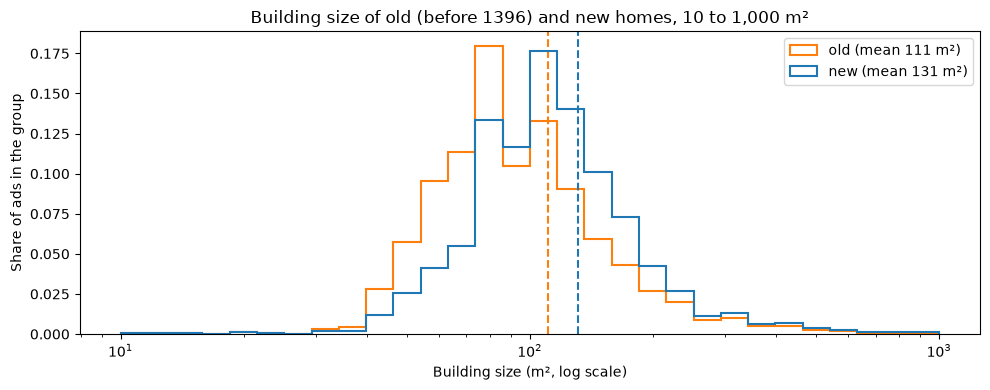

In [6]:
bins = np.logspace(1, 3, 31)
fig, ax = plt.subplots(figsize=(10, 4))
for group, color in [('old', 'tab:orange'), ('new', 'tab:blue')]:
    sizes = homes.loc[homes['age_group'] == group, 'building_size']
    # each bar is a share of the group, so both groups are comparable
    ax.hist(sizes, bins=bins, weights=np.ones(len(sizes)) / len(sizes), histtype='step',
            linewidth=1.5, color=color, label=f'{group} (mean {sizes.mean():.0f} m²)')
    ax.axvline(sizes.mean(), color=color, linestyle='--')
ax.set_xscale('log')
ax.set_xlabel('Building size (m², log scale)')
ax.set_ylabel('Share of ads in the group')
ax.set_title('Building size of old (before 1396) and new homes, 10 to 1,000 m²')
ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

- همه‌ی percentileهای جدول (از ۲۵ تا ۹۵) در گروه جدید بالاتر از گروه قدیمی است: median ۱۱۰ در برابر ۸۸ متر، و میانگین ۱۳۱ در برابر ۱۱۱ متر. کل توزیع خانه‌های جدید به سمت راست جابه‌جا شده، پس از همین‌جا پیداست که داده جهت مخالف فرضیه را نشان می‌دهد.
- توزیع متراژ right-skewed است: میانگین بالاتر از median است و دُم توزیع تا چند هزار متر ادامه دارد. پس نرمال بودن داده بعید است، و قبل از انتخاب آزمون بررسی می‌شود.

</div>

## Normality Check

<div dir="rtl">

- آزمون t فرض می‌کند داده نرمال است، پس اول نرمال بودن با آزمون Shapiro-Wilk بررسی می‌شود.
- آزمون Shapiro-Wilk برای نمونه‌های بزرگ‌تر از ۵,۰۰۰ دقیق نیست (p-value آن تقریبی می‌شود). برای همین از هر گروه یک نمونه‌ی تصادفی ۵,۰۰۰ تایی گرفته می‌شود.

</div>

In [7]:
for group in ['old', 'new']:
    sample = homes.loc[homes['age_group'] == group, 'building_size'].sample(5000, random_state=0)
    result = stats.shapiro(sample)
    print(group, 'W =', round(result.statistic, 3), 'p =', result.pvalue)

old W = 0.15 p = 4.7881406021646853e-92
new W = 0.222 p = 5.289766436815825e-90


<div dir="rtl">

- در هر دو گروه p-value عملاً صفر است، پس فرض نرمال بودن رد می‌شود؛ همان چیزی که از histogram هم انتظار داشتیم.
- به همین دلیل دو آزمون انجام می‌شود:
  - آزمون Mann-Whitney U: به نرمال بودن نیاز ندارد و روی رتبه‌ها کار می‌کند. این آزمون به‌جای میانگین، کل دو توزیع را مقایسه می‌کند، یعنی بررسی می‌کند که آیا یک خانه‌ی قدیمی تصادفی معمولاً بزرگ‌تر از یک خانه‌ی جدید تصادفی است یا نه.
  - آزمون Welch's t-test: سؤال پروژه درباره‌ی میانگین است و این آزمون مستقیم میانگین‌ها را مقایسه می‌کند. آنچه t-test واقعاً لازم دارد نرمال بودن توزیع میانگین نمونه است، و با بیش از ۳۰۰ هزار آگهی در هر گروه، طبق قضیه‌ی حد مرکزی (CLT) این شرط برقرار است. انحراف معیار دو گروه هم برابر نیست (۱۴۹ و ۱۳۷)، پس نسخه‌ی Welch استفاده می‌شود که برابری واریانس‌ها را فرض نمی‌کند.
- اگر هر دو آزمون یک نتیجه بدهند، نتیجه به فرض نرمال بودن وابسته نیست.

</div>

## Test

<div dir="rtl">

هر دو آزمون یک‌طرفه‌اند، چون فرضیه جهت دارد (قدیمی‌ها بزرگ‌ترند):

</div>

$$\text{t-test:} \quad H_0: \mu_{old} \le \mu_{new} \qquad H_1: \mu_{old} > \mu_{new}$$

$$\text{Mann-Whitney:} \quad H_0: P(X_{old} > X_{new}) = 0.5 \qquad H_1: P(X_{old} > X_{new}) > 0.5$$

<div dir="rtl">

- برای t-test، اختلاف میانگین‌ها و بازه‌ی اطمینان ۹۵ درصدی آن هم گزارش می‌شود. برای Mann-Whitney، مقدار `prob_old_larger` برابر $U / (n_{old} \cdot n_{new})$ است: احتمال اینکه یک خانه‌ی قدیمی تصادفی بزرگ‌تر از یک خانه‌ی جدید تصادفی باشد (حالت تساوی نصف حساب می‌شود). عدد ۰.۵ یعنی هیچ‌کدام از دو گروه تمایلی به بزرگ‌تر بودن ندارد.
- با این حجم نمونه اختلاف‌های خیلی کوچک هم معنادار می‌شوند، پس اندازه‌ی اختلاف از خود p-value مهم‌تر است.
- این مقایسه چند بار تکرار می‌شود (کل خانه‌ها و هر دسته جداگانه)، پس در یک تابع نوشته می‌شود.

</div>

In [8]:
def compare_groups(old, new):
    # both tests one-sided: old > new
    t, p_t = stats.ttest_ind(old, new, equal_var=False, alternative='greater')
    u, p_u = stats.mannwhitneyu(old, new, alternative='greater')
    diff = old.mean() - new.mean()
    se = np.sqrt(old.var() / len(old) + new.var() / len(new))
    return pd.Series({'n_old': len(old), 'n_new': len(new),
                      'mean_old': old.mean(), 'mean_new': new.mean(),
                      'diff': diff, 'ci_low': diff - 1.96 * se, 'ci_high': diff + 1.96 * se,
                      'p_ttest': p_t, 'prob_old_larger': u / (len(old) * len(new)), 'p_mannwhitney': p_u})

In [9]:
old = homes['age_group'] == 'old'
compare_groups(homes.loc[old, 'building_size'], homes.loc[~old, 'building_size']).round(2)

n_old              347495.00
n_new              343524.00
mean_old              110.51
mean_new              131.07
diff                  -20.57
ci_low                -21.24
ci_high               -19.89
p_ttest                 1.00
prob_old_larger         0.37
p_mannwhitney           1.00
dtype: float64

<div dir="rtl">

- در هر دو آزمون p-value برابر ۱ است، پس $H_0$ رد نمی‌شود: داده هیچ شاهدی برای بزرگ‌تر بودن خانه‌های قدیمی‌ساخت ندارد.
- وضعیت در واقع برعکس است. خانه‌های قدیمی‌ساخت به‌طور میانگین حدود ۲۱ متر مربع کوچک‌ترند و کل بازه‌ی اطمینان اختلاف (از ۲۱.۲- تا ۱۹.۹-) زیر صفر است. طبق Mann-Whitney هم فقط در حدود ۳۷ درصد جفت‌ها خانه‌ی قدیمی بزرگ‌تر است، که به‌وضوح کمتر از ۵۰ درصد است.
- دو آزمون یک نتیجه می‌دهند، پس نتیجه به فرض نرمال بودن بستگی ندارد.

</div>

## Is It the Mix of Property Types?

<div dir="rtl">

- دو گروه از نظر نوع ملک یکسان نیستند: سهم خانه و ویلای اجاره‌ای در آگهی‌های قدیمی‌ساخت تقریباً دو برابر است (۱۲ در برابر ۶ درصد)، و سهم آپارتمان فروشی کمتر (۴۰ در برابر ۴۷ درصد).
- وقتی ترکیب دو گروه فرق دارد، اختلاف کلی ممکن است فقط از همین ترکیب بیاید و درون هر دسته برعکس باشد (Simpson's paradox). برای کنترل این اثر، آزمون در هر دسته جداگانه تکرار می‌شود.

</div>

In [10]:
pd.crosstab(homes['cat3_slug'], homes['age_group'], normalize='columns').round(3)

age_group,new,old
cat3_slug,,
apartment-rent,0.283,0.317
apartment-sell,0.471,0.404
house-villa-rent,0.059,0.121
house-villa-sell,0.188,0.158


In [11]:
by_category = {}
for category, group in homes.groupby('cat3_slug'):
    is_old = group['age_group'] == 'old'
    by_category[category] = compare_groups(group.loc[is_old, 'building_size'], group.loc[~is_old, 'building_size'])
pd.DataFrame(by_category).T.round(2)

,n_old,n_new,mean_old,mean_new,diff,ci_low,ci_high,p_ttest,prob_old_larger,p_mannwhitney
apartment-rent,110228.0,97106.0,95.39,119.73,-24.34,-25.04,-23.64,1.00,0.33,1.0
apartment-sell,140343.0,161651.0,90.36,116.08,-25.72,-26.47,-24.96,1.00,0.32,1.0
house-villa-rent,41977.0,20166.0,131.36,135.45,-4.09,-7.21,-0.97,0.99,0.48,1.0
house-villa-sell,54947.0,64601.0,176.36,184.29,-7.93,-10.71,-5.15,1.00,0.48,1.0


<div dir="rtl">

- در هر چهار دسته هر دو آزمون یک نتیجه می‌دهند: p-value بین ۰.۹۹ و ۱، و میانگین خانه‌های قدیمی‌ساخت کمتر. پس نتیجه‌ی کلی ساخته‌ی ترکیب دسته‌ها نیست.
- بزرگ‌ترین اختلاف در آپارتمان‌هاست: حدود ۲۴ تا ۲۶ متر در میانگین، و `prob_old_larger` حدود ۰.۳۲ تا ۰.۳۳.
- در خانه و ویلا اختلاف کوچک است: ۴ تا ۸ متر در میانگین، و `prob_old_larger` برابر ۰.۴۸، یعنی تقریباً هیچ‌کدام از دو گروه بزرگ‌تر از دیگری نیست.

</div>

## A Closer Look at the Age Curve

<div dir="rtl">

مرز ۱۳۹۶ فقط هفت سال قبل از زمان این آگهی‌هاست (۱۴۰۳)، در حالی که «قدیما» در این جمله معمولاً به چند دهه قبل اشاره دارد. برای همین میانگین متراژ برای هر سال ساخت جداگانه رسم می‌شود، هم برای کل خانه‌ها و هم برای آپارتمان و خانه/ویلا.

</div>

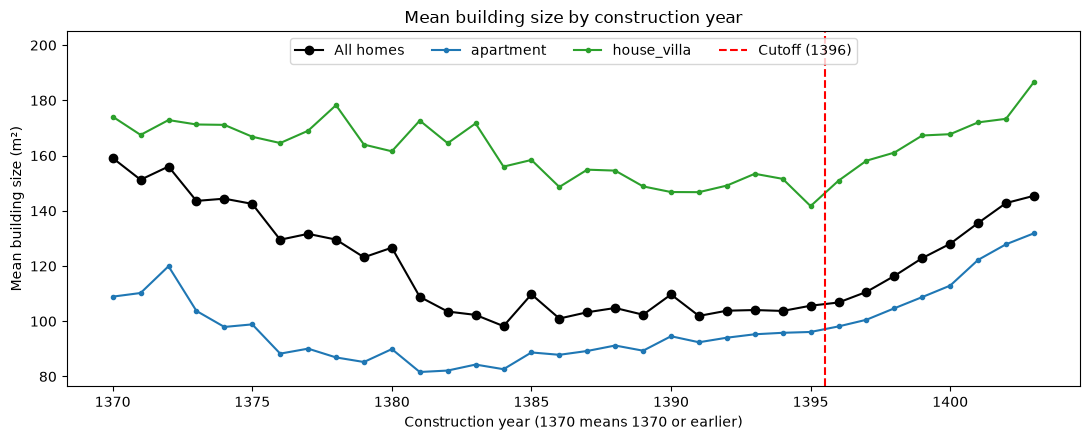

In [12]:
homes['kind'] = np.where(homes['cat3_slug'].str.startswith('apartment'), 'apartment', 'house_villa')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(homes.groupby('construction_year')['building_size'].mean(), marker='o', color='black', label='All homes')
for kind, color in [('apartment', 'tab:blue'), ('house_villa', 'tab:green')]:
    by_year = homes[homes['kind'] == kind].groupby('construction_year')['building_size'].mean()
    ax.plot(by_year, marker='.', color=color, label=kind)
ax.axvline(1395.5, color='red', linestyle='--', label='Cutoff (1396)')
ax.set_xlabel('Construction year (1370 means 1370 or earlier)')
ax.set_ylabel('Mean building size (m²)')
ax.set_ylim(top=205)
ax.set_title('Mean building size by construction year')
ax.legend(loc='upper center', ncol=4)
plt.tight_layout()
plt.show()

In [13]:
period = pd.cut(homes['construction_year'], [0, 1379, 1395, 1403],
                labels=['before 1380', '1380-1395', '1396 on'])
pd.crosstab(period, homes['kind'], values=homes['building_size'], aggfunc='mean', margins=True).round(1)

kind,apartment,house_villa,All
construction_year,,,
before 1380,100.0,171.2,147.5
1380-1395,92.2,152.5,106.5
1396 on,117.4,172.7,131.1
All,105.2,164.2,120.7


In [14]:
pd.crosstab(period, homes['kind'], normalize='index').round(2)

kind,apartment,house_villa
construction_year,,
before 1380,0.33,0.67
1380-1395,0.76,0.24
1396 on,0.75,0.25


<div dir="rtl">

- منحنی U شکل است: خانه‌های ساخت دهه‌ی ۷۰ بزرگ‌ترند، خانه‌های ۱۳۸۰ تا ۱۳۹۵ کوچک‌ترین‌اند، و از حدود ۱۳۹۶ متراژ دوباره بالا می‌رود. این الگو هم در آپارتمان و هم در خانه/ویلا دیده می‌شود.
- اگر «قدیمی» را ساخت قبل از ۱۳۸۰ بگیریم، میانگین کل با این جمله جور درمی‌آید (۱۴۸ در برابر ۱۳۱ متر). ولی این هم اثر ترکیب دسته‌هاست: ۶۷ درصد آگهی‌های ساخت قبل از ۱۳۸۰ خانه و ویلا هستند، در حالی که این سهم در آگهی‌های جدیدساخت ۲۵ درصد است.
- با مقایسه‌ی هم‌نوع‌ها، آپارتمان‌های ساخت قبل از ۱۳۸۰ (حدود ۱۰۰ متر) کوچک‌تر از آپارتمان‌های جدیدند (حدود ۱۱۷ متر)، و خانه‌ها و ویلاها در این دو دوره تقریباً هم‌اندازه‌اند.
- پس به احتمال زیاد این حس از اینجا می‌آید که خانه‌های قدیمی بیشتر ویلایی بودند و امروز بیشتر آپارتمان ساخته می‌شود، نه از کوچک‌تر شدن خود واحدها.

</div>

## Conclusion

<div dir="rtl">

- با تعریف صورت پروژه (قبل از ۱۳۹۶)، داده فرضیه را پشتیبانی نمی‌کند: نه با t-test و نه با Mann-Whitney، $H_0$ رد نمی‌شود، و در واقع خانه‌های جدیدساخت به‌طور میانگین حدود ۲۱ متر مربع بزرگ‌ترند. این نتیجه در هر چهار دسته (آپارتمان و خانه/ویلا، فروشی و اجاره‌ای) تکرار می‌شود.
- فقط خانه‌های ساخت قبل از ۱۳۸۰ به‌طور میانگین بزرگ‌تر از خانه‌های جدیدند، و آن هم به این دلیل که بیشترشان ویلایی‌اند. آپارتمان با آپارتمان، واحدهای جدید بزرگ‌ترند.
- محدودیت‌ها:
  - این داده عمدتاً آگهی‌های سال ۱۴۰۳ است، نه همه‌ی خانه‌هایی که در هر سال ساخته شده‌اند. خانه‌های قدیمی این داده آن‌هایی‌اند که هنوز پابرجا و در بازارند (survivorship bias). مثلاً خانه‌های بزرگ کلنگی که تخریب و به آپارتمان تبدیل شده‌اند دیگر در گروه قدیمی دیده نمی‌شوند.
  - آگهی‌ها کاملاً مستقل نیستند، چون چند واحد از یک ساختمان ممکن است جدا آگهی شوند. این موضوع بازه‌های اطمینان را کمی باریک‌تر از واقع نشان می‌دهد، ولی با این حجم نمونه و این اندازه‌ی اختلاف بعید است نتیجه را عوض کند.

</div>